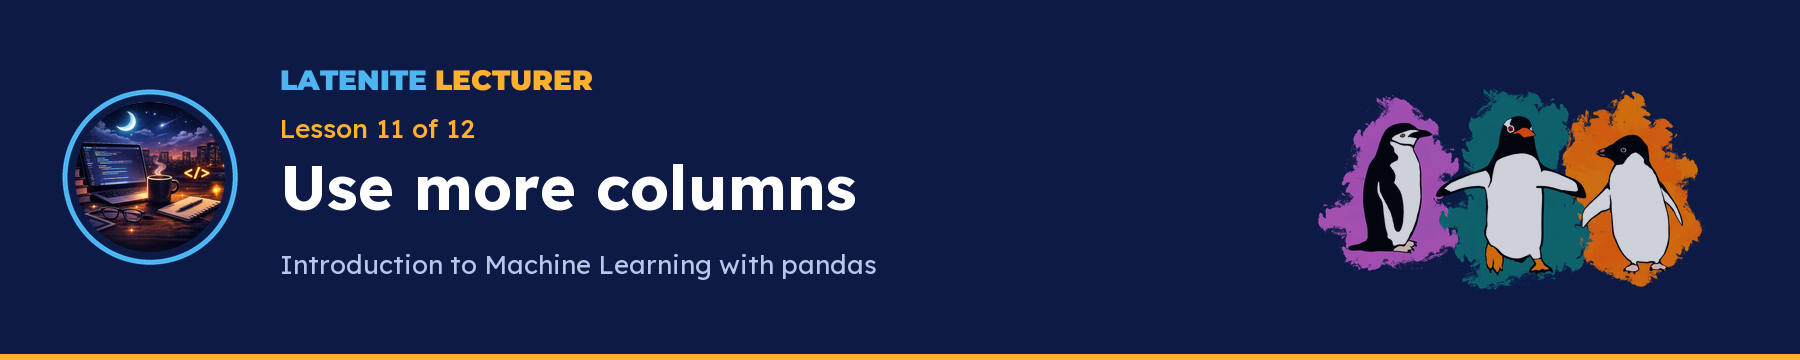
<h1 style="display:none">Lesson 11: Use more columns</h1>

**Introduction to Machine Learning with pandas** (lesson 11 of 12)

By the end you can turn a text column into number columns, and compare two models on the same test rows.

The first two cells open the clean table, `penguins_clean.csv`.

In [ ]:
import pandas as pd

In [ ]:
penguins = pd.read_csv("penguins_clean.csv")

## 1. Encode the text column

`pd.get_dummies` leaves number columns as they are, and turns each text column into one `True` or `False` column for each category. A model can read those, because `True` counts as 1 and `False` as 0.

Each new column is named after the old column and the category: `island_Biscoe` is "island" plus "Biscoe".

In [ ]:
columns = ["bill_depth_mm", "body_mass_g", "island"]
chosen = penguins[columns]
X = pd.get_dummies(chosen)
X.head()

## 2. Choose the target and split the rows

Encode first, then split. If you split first, a category that appears only in the training rows gets a column the test rows lack, and the model cannot score them.

In [ ]:
from sklearn.model_selection import train_test_split
y = penguins["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

## 3. Fit the small tree

The tree from lesson 10, now with the island columns as well.

**Pause and reflect:** before you run it, guess whether the island helps. Lesson 10's tree scored 0.78.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
tree_score = tree.score(X_test, y_test)
round(tree_score, 2)

## 4. Fit a random forest

A random forest trains many trees and lets them vote. `ensemble` in the import line means a group of models. Only the first two lines differ from the cell above.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
forest = RandomForestClassifier(random_state=42)
forest.fit(X_train, y_train)
forest_score = forest.score(X_test, y_test)
round(forest_score, 2)

## 5. See where the forest is right

The confusion matrix for the forest. Rows are the true species, and columns are the predictions.

In [ ]:
from sklearn.metrics import confusion_matrix
predicted = forest.predict(X_test)
matrix = confusion_matrix(y_test, predicted)
species_names = forest.classes_
table = pd.DataFrame(matrix, index=species_names, columns=species_names)
table

## Task: add a text column to your own features

1. Open `my_data.ipynb` and run its cells (Run All).
2. Add the cell below in place of your old features, above the split. Change `"penguins_clean.csv"` to your file, and the list to your own feature columns, with one text column among them.
3. Run the split, fit and score cells again. If the score rises, the text column carried information the model could use. If it does not change, or falls, the column told the model nothing new; keep it out.

In [ ]:
my_data = pd.read_csv("penguins_clean.csv")
columns = ["bill_length_mm", "flipper_length_mm", "sex"]
chosen = my_data[columns]
X = pd.get_dummies(chosen)
X.head()